# ShieldZ: real-time payment protection that keeps no personal data

This notebook walks through the system on IBM LinuxONE (s390x), step by step. It runs the same code as the service: the notebook only calls it and displays the results. It works in a scratch folder, so it never touches the live demo's files.

1. One payment in detail: what goes in, and what the system keeps
2. The four demo payments
3. What the model alone would have decided
4. Real-time decisions
5. The privacy proof: a Canary Leak Audit, run live
6. Tamper evidence
7. The committed evidence from the full runs

In [1]:
import io, json, os, platform, shutil, sys, tempfile, time, uuid, warnings
from pathlib import Path

import pandas as pd
from IPython.display import Markdown, display

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", None)

print("Machine architecture :", platform.machine())
print("Operating system     :", platform.platform())
print("Python               :", sys.version.split()[0])
print("CPU cores visible    :", os.cpu_count())
import numpy, xgboost
print("numpy / pandas / xgboost :", numpy.__version__, "/", pd.__version__, "/", xgboost.__version__)

Machine architecture : s390x
Operating system     : Linux-6.8.0-147-generic-s390x-with-glibc2.39
Python               : 3.12.15
CPU cores visible    : 3


numpy / pandas / xgboost : 2.0.2 / 3.0.6 / 3.4.1


In [2]:
# Find the repository, and work in a scratch folder so the live demo's files are never touched.
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "shieldz").exists())
sys.path[:0] = [str(REPO / "src"), str(REPO / "scripts")]

WORK = Path(tempfile.mkdtemp(prefix="shieldz_notebook_"))
model_dir = REPO / "artifacts" / "model"
ENGINE = "xgboost" if (model_dir / "model.json").exists() else "stub"
if ENGINE == "xgboost":
    shutil.copytree(model_dir, WORK / "model")

os.environ.update(SHIELDZ_ARTIFACTS=str(WORK), SHIELDZ_ENGINE=ENGINE,
                  SHIELDZ_EXPLAINER="template", SHIELDZ_RESULTS=str(REPO / "results"))
print("Repository :", REPO)
print("Scratch    :", WORK)
print("Engine     :", "the trained XGBoost model" if ENGINE == "xgboost"
      else "the rule-based stand-in (no trained model found on this machine)")

Repository : /home/jovyan/shared/ShieldZ
Scratch    : /tmp/shieldz_notebook_fa2d0_ae
Engine     : the trained XGBoost model


In [3]:
# Start the service in this notebook (the same app the demo page talks to).
from fastapi.testclient import TestClient
from shieldz.privacy.redact_log import setup_logging
from shieldz.service.app import create_app
from shieldz.service.pipeline import Pipeline

setup_logging(WORK / "runtime" / "logs" / "app.jsonl", io.StringIO())  # log to a file, keep the notebook quiet
pipeline = Pipeline.from_env()
pipeline.signer = None   # see the note below
client = TestClient(create_app(pipeline))
client.__enter__()
client.get("/healthz").json()

{'status': 'ok',
 'platform': 's390x',
 'engine': 'xgboost',
 'model_version': 'xgb-v1'}

*A note on signing.* The service signs checkpoints of the audit chain with Ed25519. That needs a fast crypto library, which this Jupyter image does not have (the service image installs it). Pure-Python signing would stall requests by about 250 ms and distort the timing in part 4, so signing is switched off in this notebook. The hash chain itself is still written and verified (part 6). The signed checkpoints are verified on the full runs in part 7.

## 1. One payment in detail

A scam payment with distinctive personal data: a name, phone number, accounts, a memo and a family contact. We send it, then look at what the system returns and what it stored.

In [4]:
payment = {
    "payer_name": "Zubin Qureshi", "payer_phone": "+91 98123 45678", "payer_account": "ACC-5550-1234-9988",
    "payee_name": "Supreme Court Clearance Escrow", "payee_account": f"UPI-escrow-{uuid.uuid4().hex[:6]}@okaxis",
    "memo": "URGENT VERIFICATION DEPOSIT CANARY-7f3a91", "family_contact": "+91 98123 00011 (Son: Ravi)",
    "tx_type": "TRANSFER", "amount": 485000.00, "payer_balance_before": 485000.00,
    "payee_balance_before": 0.0, "payee_is_merchant": False,
    "timestamp": "2026-10-18T02:45:00+05:30", "language": "EN",
}
response = client.post("/v1/score", json=payment)
decision = response.json()
print(json.dumps(decision, indent=2))

{
  "decision_id": "1f663e50a46e49cb9fae215055dc9d18",
  "decision": "BLOCK",
  "risk_level": "HIGH",
  "reason_codes": [
    {
      "code": "AMOUNT_HIGH_VS_BALANCE",
      "level": "HIGH"
    },
    {
      "code": "MULE_ACCOUNT_PATTERN",
      "level": "HIGH"
    },
    {
      "code": "ACCOUNT_DRAIN",
      "level": "HIGH"
    }
  ],
  "model_version": "xgb-v1",
  "server_ms": 2.706
}


In [5]:
records = client.get(f"/v1/records/{decision['decision_id']}").json()
print("The record stored for this payment (read back from the audit chain):")
print(json.dumps(records["audit"], indent=2))

The record stored for this payment (read back from the audit chain):
{
  "decision": "BLOCK",
  "decision_id": "1f663e50a46e49cb9fae215055dc9d18",
  "hash": "95dcfd865190ebe594c3c9eaf7e960276454b13c51d3553b68d1a2f6aaf0a6bf",
  "model_version": "xgb-v1",
  "prev_hash": "0000000000000000000000000000000000000000000000000000000000000000",
  "reason_codes": [
    {
      "code": "AMOUNT_HIGH_VS_BALANCE",
      "level": "HIGH"
    },
    {
      "code": "MULE_ACCOUNT_PATTERN",
      "level": "HIGH"
    },
    {
      "code": "ACCOUNT_DRAIN",
      "level": "HIGH"
    }
  ],
  "risk_level": "HIGH",
  "seq": 0,
  "ts": "2026-10-18T09:44:56Z"
}


Now the check. We search every file the service wrote, byte by byte, for each personal value we typed. Databases are included. A search is only convincing if it can find something that *is* there, so we also plant one value on purpose.

In [6]:
def search(root: Path, values: dict) -> pd.DataFrame:
    """Which files under `root` contain each value anywhere in their bytes."""
    files = [f for f in root.rglob("*") if f.is_file()]
    rows = []
    for value in values.values():
        hits = [str(f.relative_to(root)) for f in files if value.encode() in f.read_bytes()]
        rows.append({"value typed": value, "found in": ", ".join(hits) or "nowhere"})
    return pd.DataFrame(rows)

typed = {k: payment[k] for k in ("payer_name", "payer_phone", "payer_account", "payee_name",
                                 "payee_account", "memo", "family_contact")}
display(search(WORK / "runtime", typed))

# The control: plant one value on purpose. The search must find it.
planted = WORK / "runtime" / "planted_control.txt"
planted.write_text("control: " + payment["payer_phone"])
display(search(WORK / "runtime", {"payer_phone": payment["payer_phone"]}))
planted.unlink()

everything_returned = response.text + json.dumps(records)
print("Typed values found in the API response or the stored record:",
      [v for v in typed.values() if v in everything_returned] or "none")

,value typed,found in
0,Zubin Qureshi,nowhere
1,+91 98123 45678,nowhere
2,ACC-5550-1234-9988,nowhere
3,Supreme Court Clearance Escrow,nowhere
4,UPI-escrow-392cbe@okaxis,nowhere
5,URGENT VERIFICATION DEPOSIT CANARY-7f3a91,nowhere
6,+91 98123 00011 (Son: Ravi),nowhere


,value typed,found in
0,+91 98123 45678,planted_control.txt


Typed values found in the API response or the stored record: none


## 2. The four demo payments

The same four payments as the demo page. Each uses a fresh payee, because once a payee has been paid they count as known.

In [7]:
import demo_scenarios

rows = []
for sc in demo_scenarios.SCENARIOS.values():
    p = dict(sc.payment)
    if p["payee_account"] != demo_scenarios.SEEDED_PAYEE:
        p["payee_account"] += "-" + uuid.uuid4().hex[:4]
    d = client.post("/v1/score", json=p).json()
    rows.append({"payment": sc.title.split(": ", 1)[1], "expected": sc.expected_decision.value,
                 "decision": d["decision"], "reasons": ", ".join(r["code"] for r in d["reason_codes"]) or "none",
                 "ms": d["server_ms"], "as expected": d["decision"] == sc.expected_decision.value})
scenarios = pd.DataFrame(rows)
scenarios

,payment,expected,decision,reasons,ms,as expected
0,'Digital Arrest' Imposter Scam,BLOCK,BLOCK,"AMOUNT_HIGH_VS_BALANCE, MULE_ACCOUNT_PATTERN, ACCOUNT_DRAIN",1.250,True
1,Routine Monthly Electricity Bill,ALLOW,ALLOW,none,0.349,True
2,Urgent Diagnostic Clinic Payment While Traveling,ALLOW,ALLOW,none,0.297,True
3,Large Transfer to a Brand-New Account,REVIEW,REVIEW,"NEW_RECIPIENT, LARGE_AMOUNT",0.466,True


## 3. What the model alone would have decided

The detector learned one pattern very well: an account being emptied. Anything else, it scores low. So a large partial transfer to a stranger would be allowed by the model alone. A small policy rule next to the model covers that case: a **first payment to a new payee** that is **at least 40% of the balance** and **at least Rs 10,000** is held for review. An ordinary payment to a new payee, such as the clinic bill, is untouched.

In [8]:
from shieldz.features import engineer
from shieldz.privacy import default_tokenizer, strip
from shieldz.service.decide import decide, load_thresholds
from shieldz.service.pipeline import build_history, load_engine

engine, thresholds, tokenizer = load_engine(), load_thresholds(), default_tokenizer()
print(f"engine: {engine.name} {engine.version} | review from {thresholds.t_review}, block from {thresholds.t_block}")
print(f"policy rule: new payee AND >= {thresholds.review_new_payee_ratio:.0%} of the balance "
      f"AND >= Rs {thresholds.review_new_payee_min_amount:,.0f}")

rows = []
for sc, final in zip(demo_scenarios.SCENARIOS.values(), scenarios["decision"]):
    features = engineer(strip(sc.to_payment_request(), tokenizer), build_history(tokenizer))
    score = engine.score(features)
    rows.append({"payment": sc.title.split(": ", 1)[1], "model score": round(score, 3),
                 "model alone": decide(score, thresholds)[0].value, "final decision": final})
pd.DataFrame(rows)

engine: xgboost xgb-v1 | review from 0.7, block from 0.75
policy rule: new payee AND >= 40% of the balance AND >= Rs 10,000


,payment,model score,model alone,final decision
0,'Digital Arrest' Imposter Scam,0.973,BLOCK,BLOCK
1,Routine Monthly Electricity Bill,0.027,ALLOW,ALLOW
2,Urgent Diagnostic Clinic Payment While Traveling,0.027,ALLOW,ALLOW
3,Large Transfer to a Brand-New Account,0.125,ALLOW,REVIEW


In [9]:
# How much does the model add over simple rules? (measured on the VM, same holdout as the model card)
path = REPO / "results" / "baseline_comparison.md"
display(Markdown(path.read_text())) if path.exists() else print("results/baseline_comparison.md not found")

# Baseline comparison: what does the model add?

Time-based holdout (step > 600): 103,573 rows, 1,600 fraud. Produced by `scripts/baseline_compare.py` on the LinuxONE VM.

| Detector | Fraud caught | Recall | False alarms | Precision | PR-AUC |
|---|---|---|---|---|---|
| Rule: TRANSFER/CASH_OUT, account drained | 1542/1600 | 0.9637 | 37,063 | 0.040 | n/a |
| Rule: the above, and payee balance is zero | 1014/1600 | 0.6338 | 6,269 | 0.139 | n/a |
| Rule: TRANSFER/CASH_OUT, amount >= 99% of balance | 1542/1600 | 0.9637 | 37,114 | 0.040 | n/a |
| Decision tree, depth 2 (learned if/else) | 1542/1600 | 0.9637 | 1 | 0.999 | 0.9645 |
| Decision tree, depth 3 (learned if/else) | 1591/1600 | 0.9944 | 5 | 0.997 | 0.9945 |
| Decision tree, depth 4 (learned if/else) | 1599/1600 | 0.9994 | 4 | 0.998 | 0.9994 |
| **ShieldZ XGBoost** (block at 0.75) | 1598/1600 | 0.9988 | 79 | 0.953 | 0.9944 |

**Reading it.** Obvious hand-written rules are poor (tens of thousands of false alarms, because many legitimate PaySim transfers also empty an account). But a learned decision tree of depth 3 matches our XGBoost model and depth 4 beats it. PaySim fraud is close to a threshold pattern, so the model is not where ShieldZ's value is. We claim the architecture (privacy barrier, leak audit, signed audit trail, on-platform real-time decisions), not detection accuracy.


## 4. Real-time decisions

500 different payments, one after another. `server_ms` is the time the service itself measured for each decision. The caller-side column includes the in-process call overhead. This is not a network measurement; the HTTP numbers measured on the VM are shown below the chart.

,inside the service,"caller side, in-process"
p50,0.29,1.00
p95,0.84,1.61
p99,1.00,2.10
max,28.87,29.67


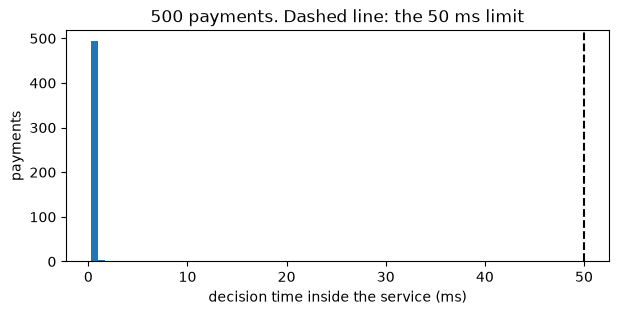

In [10]:
import random
import matplotlib.pyplot as plt
import numpy as np
import bench_latency

rng = random.Random(7)
server_ms, caller_ms = [], []
for i in range(500):
    t0 = time.perf_counter()
    r = client.post("/v1/score", json=bench_latency.make_payment(rng, i))
    caller_ms.append((time.perf_counter() - t0) * 1000)
    server_ms.append(r.json()["server_ms"])

def pcts(x):
    return {"p50": np.percentile(x, 50), "p95": np.percentile(x, 95), "p99": np.percentile(x, 99), "max": max(x)}

display(pd.DataFrame({"inside the service": pcts(server_ms), "caller side, in-process": pcts(caller_ms)}).round(2))

fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(server_ms, bins=40)
ax.axvline(50, color="black", linestyle="--")
ax.set_xlabel("decision time inside the service (ms)")
ax.set_ylabel("payments")
ax.set_title("500 payments. Dashed line: the 50 ms limit")
plt.show()

In [11]:
# The same benchmark over HTTP on the VM, committed in results/ (5,000 requests per row).
rows = []
for name, label in (("latency_real.json", "idle"), ("latency_busy.json", "while Granite is generating")):
    f = REPO / "results" / name
    if f.exists():
        data = json.loads(f.read_text())
        for c, level in data["levels"].items():
            rows.append({"run": label, "requests at a time": c, "p50 ms": level["client_ms"]["p50"],
                         "p99 ms": level["client_ms"]["p99"], "errors": level["errors"], "platform": data["platform"]})
pd.DataFrame(rows)

,run,requests at a time,p50 ms,p99 ms,errors,platform
0,idle,1,1.559,6.896,0,s390x
1,idle,8,6.624,21.830,0,s390x
2,while Granite is generating,1,1.514,11.523,0,s390x
3,while Granite is generating,8,7.348,23.373,0,s390x


## 5. The privacy proof: a Canary Leak Audit, run live

We send 100 fake customers (unique names, numbers and memos) through the real system, then search every place it writes data for them. We also search for 100 look-alike values that were **never sent** (they must not match), and we hide 10 canaries on purpose in a known file (they must be found). The full run used 1,000 customers; this one is smaller so it finishes in a moment.

In [12]:
import contextlib
client.__exit__(None, None, None)   # stop the first service; the audit starts its own
from shieldz.leak_audit.replay import run_leak_audit
from shieldz.service.live_replay import live_pipeline_fn

audit_runtime = WORK / "audit_runtime"
with contextlib.redirect_stdout(io.StringIO()):   # the service prints one log line per decision
    send, close = live_pipeline_fn(audit_runtime)
    try:
        card = run_leak_audit(audit_runtime, pipeline_fn=send, n_canaries=100, n_decoys=100,
                              environment="notebook", results_dir=WORK / "audit_results")
    finally:
        close()

display(pd.DataFrame([
    ["fake customers sent through", card.records_replayed],
    ["places searched", f"{card.sinks_scanned} ({card.total_bytes_scanned:,} bytes)"],
    ["leaks found (exact / variant / partial)", f"{card.leaks_exact} / {card.leaks_variant} / {card.leaks_partial}"],
    ["planted canaries found", f"{card.positive_control_found} of {card.positive_control_planted}"],
    ["never-sent decoys matched", f"{card.negative_control_hits} of {card.negative_control_decoys}"],
    ["overall", card.status],
], columns=["check", "result"]))
pd.Series(card.bytes_per_sink, name="bytes searched").to_frame()

,check,result
0,fake customers sent through,100
1,places searched,"11 (496,786 bytes)"
2,leaks found (exact / variant / partial),0 / 0 / 0
3,planted canaries found,10 of 10
4,never-sent decoys matched,0 of 100
5,overall,PASS


,bytes searched
app_log,36326
audit_chain,42096
prompt_journal,65485
outbox_sqlite,118784
history_sqlite,36864
http_responses,131434
catch_all:outbox.sqlite-wal,0
catch_all:history.sqlite-wal,0
catch_all:outbox.sqlite-shm,32768
catch_all:history.sqlite-shm,32768


## 6. Tamper evidence

Every decision above was added to a hash chain: each entry carries a fingerprint of itself and of the entry before it. We verify the real chain, then damage copies of it in three ways. Each change is caught, and the verifier reports where the chain breaks.

In [13]:
from shieldz.audit.verify import verify_audit_trail

chain = WORK / "runtime" / "audit" / "chain.jsonl"

def check(path):
    ok, message, seq = verify_audit_trail(path, None, None)
    return ("PASS" if ok else f"FAIL at entry {seq}") + " | " + message[:110]

lines = chain.read_text().splitlines()
copy = WORK / "tampered_chain.jsonl"
print(f"entries in the chain: {len(lines)}")
print("intact chain         :", check(chain))

entry = json.loads(lines[100])
entry["decision"] = "ALLOW" if entry["decision"] != "ALLOW" else "BLOCK"
edited = lines.copy()
edited[100] = json.dumps(entry, sort_keys=True, separators=(",", ":"))
copy.write_text("\n".join(edited) + "\n")
print("one decision changed :", check(copy))

copy.write_text("\n".join(lines[:200] + lines[201:]) + "\n")
print("one entry deleted    :", check(copy))

swapped = lines.copy()
swapped[300], swapped[301] = swapped[301], swapped[300]
copy.write_text("\n".join(swapped) + "\n")
print("two entries swapped  :", check(copy))

entries in the chain: 505
intact chain         : PASS | Chain valid: 505 entries verified OK
one decision changed : FAIL at entry 100 | Hash mismatch at seq 100: stored 11d7fe61ba2167de2db3f123a1e19c5fceb5517b29e9f7826fe8a443e4f37810 != recompute
one entry deleted    : FAIL at entry 201 | Sequence break: entry 200 has seq 201 (expected 200)
two entries swapped  : FAIL at entry 301 | Sequence break: entry 300 has seq 301 (expected 300)


## 7. The committed evidence from the full runs

The numbers below are read from the files in `results/`. They were measured on the LinuxONE VM with the full model, the Granite worker and the signed audit trail.

In [14]:
res = REPO / "results"

def load(name):
    f = res / name
    return json.loads(f.read_text()) if f.exists() else None

def text(name):
    f = res / name
    return f.read_text().strip().splitlines()[0] if f.exists() else "(file not found)"

real, busy, leak, metrics = (load(n) for n in ("latency_real.json", "latency_busy.json",
                                               "leak_scorecard_linuxone.json", "model_metrics.json"))
rows = []
if real:
    rows.append(["Decision latency over HTTP, idle (p99, 1 and 8 at a time)",
                 f"{real['levels']['1']['client_ms']['p99']} ms and {real['levels']['8']['client_ms']['p99']} ms",
                 "latency_real.json"])
if busy:
    rows.append(["The same, while Granite is generating",
                 f"{busy['levels']['1']['client_ms']['p99']} ms and {busy['levels']['8']['client_ms']['p99']} ms",
                 "latency_busy.json"])
if leak:
    n = leak["leaks_exact"] + leak["leaks_variant"] + leak["leaks_partial"]
    rows.append(["Canary Leak Audit on the VM",
                 f"{n} leaks in {leak['sinks_scanned']} places ({leak['total_bytes_scanned']:,} bytes); "
                 f"canaries {leak['positive_control_found']}/{leak['positive_control_planted']}; "
                 f"decoys matched {leak['negative_control_hits']}/{leak['negative_control_decoys']}",
                 "leak_scorecard_linuxone.json"])
if metrics:
    rows.append(["Detector on a time-based holdout",
                 f"PR-AUC {metrics['pr_auc']}, recall {metrics['recall_at_1pct_fpr']} at 1% false alarms",
                 "model_metrics.json"])
rows.append(["Audit chain and signatures on the VM", text("audit_verify_linuxone.txt"), "audit_verify_linuxone.txt"])
rows.append(["Cost of one audit append", text("audit_append_bench.txt"), "audit_append_bench.txt"])
pd.DataFrame(rows, columns=["check", "result", "file in results/"])

,check,result,file in results/
0,"Decision latency over HTTP, idle (p99, 1 and 8 at a time)",6.896 ms and 21.83 ms,latency_real.json
1,"The same, while Granite is generating",11.523 ms and 23.373 ms,latency_busy.json
2,Canary Leak Audit on the VM,"0 leaks in 11 places (3,760,623 bytes); canaries 10/10; decoys matched 0/1000",leak_scorecard_linuxone.json
3,Detector on a time-based holdout,"PR-AUC 0.9944, recall 0.9994 at 1% false alarms",model_metrics.json
4,Audit chain and signatures on the VM,VERIFY PASS: Chain valid: 22062 entries verified OK (183 checkpoint signatures valid),audit_verify_linuxone.txt
5,Cost of one audit append,"AuditChain.append x5000 on s390x: p50 0.021 ms, p99 0.033 ms (gate: p99 <= 1 ms)",audit_append_bench.txt


## What this shows, and what it does not

**It shows** that personal data is read in one place and does not appear in anything the system writes or returns; that decisions take a few milliseconds; that the model's blind spot is covered by a small, explicit rule; and that any edit, deletion or reordering in the audit trail is detected and located.

**It does not show** detection accuracy on real fraud (the training data is synthetic, and a depth-3 decision tree matches the model), protection of data in memory or on the network (the audit searches files), or that the audit trail is tamper-proof (it is tamper-evident). The Granite explainer is covered by `results/granite_quality.md`.

In [15]:
shutil.rmtree(WORK, ignore_errors=True)
print("scratch folder removed")

scratch folder removed
